<a href="https://colab.research.google.com/github/janhavipatkar854/CSL701-CS42-Machine-Learning-Lab/blob/main/ML_Experiment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Experiment Number 3

name : janhavi patkar
batch : cs03
roll no : cs42

**Aim** : To implement a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars using multiple features from the CarDekho Used Car Dataset.


**Learning Outcomes**
•	Understand the working principle of Multiple Linear Regression.

•	Perform data preprocessing and feature engineering.

•	Convert categorical data into numerical features.

•	Standardize numerical features.

•	Implement the Ordinary Least Squares method using matrix operations.

•	Train and test a regression model without using a ready-made regression function.

•	Evaluate and interpret regression performance using RSS and R².

•	Understand the effect of individual features on the predicted price.



\### Dataset

Use the **CarDekho Used Car Dataset** (`car data.csv`). [CarDekho Used Car Dataset](https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data)

Explain meaning of each attribute in this dataset in below comment section :


Here, **Selling_Price** is the target variable.





\# Software/Tools Required

- Python 3.x
- Google Colab / Jupyter Notebook
- NumPy
- Matplotlib

---


### Task 1: Set Up the Python Environment**

- Create a new Google Colab notebook.
- Import **NumPy** for numerical and matrix operations.
- Import **Matplotlib** for data visualization.
- Do not use ready-made machine-learning regression functions such as `LinearRegression()` from Scikit-learn.
- The regression model must be implemented using matrix operations.

---

In [1]:

# Task 1: Set Up the Python Environment

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display NumPy version
print("NumPy version:", np.__version__)

# Display Pandas version
print("Pandas version:", pd.__version__)

# Load the dataset
df = pd.read_csv('/content/cardekho_dataset.csv')

# Display first five rows
print("\nFirst five rows of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset shape:", df.shape)

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()


NumPy version: 2.1.3
Pandas version: 2.2.3

First five rows of the dataset:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000



Dataset shape: (15411, 14)

Dataset columns:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power   

## Task 2: Load and Inspect the Dataset

- Download the `car data.csv` file.
- Upload the dataset to Google Colab.
- Load the dataset into Python.
- Display the first few records.
- Determine the number of rows and columns.
- Identify the numerical and categorical attributes.
- Separate `Selling_Price` as the target variable.

---

In [10]:

# Task 2: Load and Inspect the Dataset

# Step 1: Import libraries
import pandas as pd
import numpy as np
import os

# Step 2: Locate the uploaded dataset
if os.path.exists('/content/car data.csv'):
    file_path = '/content/car data.csv'
elif os.path.exists('/content/cardekho_dataset.csv'):
    file_path = '/content/cardekho_dataset.csv'
elif os.path.exists('/content/cardekho_dataset.csv.csv'):
    file_path = '/content/cardekho_dataset.csv.csv'
else:
    raise FileNotFoundError(
        "Dataset not found. Please upload your CSV file to Google Colab."
    )

# Step 3: Load the dataset
df = pd.read_csv(file_path)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("File:", file_path)

# Step 4: Display the first five records
print("\nFirst five records:")
display(df.head())

# Step 5: Determine the number of rows and columns
print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Step 6: Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Step 7: Identify numerical attributes
numerical_attributes = df.select_dtypes(
    include=[np.number]
).columns.tolist()

print("\nNumerical attributes:")
print(numerical_attributes)

# Step 8: Identify categorical attributes
categorical_attributes = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nCategorical attributes:")
print(categorical_attributes)

# Step 9: Display dataset information
print("\nDataset information:")
df.info()

# Step 10: Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Step 11: Separate target and input features
# Handles selling_price and Selling_Price
target_column = next(
    (col for col in df.columns
     if col.strip().lower() == 'selling_price'),
    None
)

if target_column is None:
    raise KeyError(
        "Target column not found. Available columns: "
        + str(df.columns.tolist())
    )

# Target variable
y = df[target_column].copy()

# Input features
X = df.drop(columns=[target_column]).copy()

# Step 12: Display the separated data
print("\nTarget variable:", target_column)
print("Target shape:", y.shape)

print("\nInput feature columns:")
print(X.columns.tolist())
print("Input feature shape:", X.shape)

print("\nFirst five target values:")
display(y.head())

print("\nFirst five input records:")
display(X.head())

print("\nTask 2 completed successfully!")


Dataset loaded successfully!
File: /content/cardekho_dataset.csv

First five records:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000



Number of rows: 15411
Number of columns: 14

Column names:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Numerical attributes:
['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Categorical attributes:
['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_

,selling_price
0,120000
1,550000
2,215000
3,226000
4,570000



First five input records:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5



Task 2 completed successfully!


## Task 3: Check and Handle Missing Data

- Check every attribute for missing or null values.
- Count the number of missing values in each column.
- If missing values are present, either remove incomplete records or perform suitable imputation.
- Verify that the final dataset does not contain missing values.
- Record the preprocessing method used.

---

In [6]:

# Task 3: Check and Handle Missing Data

import pandas as pd
import numpy as np

# 1. Check missing values before preprocessing
print("Missing Values Before Preprocessing:")
missing_before = df.isnull().sum()
print(missing_before)

print("\nTotal missing values:", df.isnull().sum().sum())

# 2. Handle missing values
# Numerical columns: replace missing values with column median
numerical_cols = df.select_dtypes(include=[np.number]).columns

for col in numerical_cols:
    if df[col].isnull().any():
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)

# Categorical columns: replace missing values with mode
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

for col in categorical_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode(dropna=True)

        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
        else:
            df[col] = df[col].fillna('Unknown')

# 3. Verify missing values after preprocessing
print("\nMissing Values After Preprocessing:")
missing_after = df.isnull().sum()
print(missing_after)

print("\nTotal missing values after preprocessing:",
      df.isnull().sum().sum())

# 4. Display preprocessing summary
print("\nPreprocessing Method Used:")
print("- Numerical columns: Missing values replaced with median.")
print("- Categorical columns: Missing values replaced with mode.")
print("- If a categorical column contains only missing values,")
print("  missing entries are replaced with 'Unknown'.")

# 5. Verify dataset
if df.isnull().sum().sum() == 0:
    print("\nVerification successful: No missing values remain.")
else:
    print("\nWarning: Some missing values still remain.")

# 6. Refresh X and y after preprocessing
if 'Selling_Price' in df.columns:
    y = df['Selling_Price'].copy()
    X = df.drop(columns=['Selling_Price']).copy()

print("\nFinal dataset shape:", df.shape)
display(df.head())


Missing Values Before Preprocessing:
Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Total missing values: 0

Missing Values After Preprocessing:
Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Total missing values after preprocessing: 0

Preprocessing Method Used:
- Numerical columns: Missing values replaced with median.
- Categorical columns: Missing values replaced with mode.
- If a categorical column contains only mi

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


## Task 4: Select and Prepare Features

- Examine all available attributes.
- Decide how `Car_Name` should be handled.
- Select meaningful predictor variables for the regression model.
- Create the predictor matrix $X$ and target vector $y$.
- Record the final list of features selected for the model.

---

In [11]:

# Task 4: Select and Prepare Features

import pandas as pd
import numpy as np

# Step 1: Examine all available attributes
print("Available attributes:")
print(df.columns.tolist())

print("\nData types of attributes:")
print(df.dtypes)

# Step 2: Identify the target column
target_column = next(
    (col for col in df.columns
     if col.strip().lower() == 'selling_price'),
    None
)

if target_column is None:
    raise KeyError("Selling_Price column was not found.")

# Step 3: Handle Car_Name if present
car_name_columns = [
    col for col in df.columns
    if col.strip().lower() in ['car_name', 'name']
]

if car_name_columns:
    print("\nCar name columns found:", car_name_columns)
    print("Decision: Exclude car name columns from predictors.")
else:
    print("\nNo Car_Name column found in this dataset.")

# Step 4: Select meaningful predictors
# Exclude the target and car-name/identifier text columns
excluded_columns = [target_column] + car_name_columns

X_raw = df.drop(columns=excluded_columns).copy()
y = pd.to_numeric(df[target_column], errors='coerce')

# Step 5: Convert numeric-looking columns to numeric where possible
for col in X_raw.columns:
    if X_raw[col].dtype == 'object':
        converted = pd.to_numeric(X_raw[col], errors='coerce')

        # Convert only when all existing non-null values are numeric
        if converted.notna().sum() == X_raw[col].notna().sum():
            X_raw[col] = converted

# Step 6: Encode categorical predictors using one-hot encoding
categorical_columns = X_raw.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nCategorical predictors to encode:")
print(categorical_columns)

X = pd.get_dummies(
    X_raw,
    columns=categorical_columns,
    drop_first=True,
    dtype=float
)

# Step 7: Ensure target and predictors are valid numeric data
X = X.apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(y, errors='coerce')

# Replace infinite values and remove rows with invalid data
X = X.replace([np.inf, -np.inf], np.nan)
y = y.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows].astype(float)
y = y.loc[valid_rows].astype(float)

# Step 8: Display final predictor matrix and target vector
print("\nFinal predictor features:")
print(X.columns.tolist())

print("\nNumber of predictor columns:", X.shape[1])
print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFirst five rows of X:")
display(X.head())

print("\nFirst five values of y:")
display(y.head())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nTask 4 completed successfully!")


Available attributes:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Data types of attributes:
Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

Car name columns found: ['car_name']
Decision: Exclude car name columns from predictors.

Categorical predictors to encode:
['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

Final predictor features:
['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'brand_BMW', 'brand_Bentley', 'brand_Datsun

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_BMW,brand_Bentley,brand_Datsun,...,model_i10,model_i20,model_redi-GO,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
0,0.0,9.0,120000.0,19.70,796.0,46.30,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
1,1.0,5.0,20000.0,18.90,1197.0,82.00,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
2,2.0,11.0,60000.0,17.00,1197.0,80.00,5.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
3,3.0,9.0,37000.0,20.92,998.0,67.10,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
4,4.0,6.0,30000.0,22.77,1498.0,98.59,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0



First five values of y:


,selling_price
0,120000.0
1,550000.0
2,215000.0
3,226000.0
4,570000.0



Missing values in X: 0
Missing values in y: 0

Task 4 completed successfully!


## Task 5: Encode Categorical Variables

Identify the categorical variables:

- `Fuel_Type`
- `Seller_Type`
- `Transmission`

Perform the following:

- Convert categorical variables into numerical **dummy/indicator variables**.
- Verify that all predictors are numerical after encoding.
- Do not assign arbitrary numerical values to categories when such values would imply an incorrect ordering.
- Display the transformed dataset.

---

In [12]:

# Task 5: Encode Categorical Variables

import pandas as pd
import numpy as np

# Step 1: Identify categorical columns
print("Available columns:")
print(df.columns.tolist())

# Find the target column
target_column = next(
    (col for col in df.columns
     if col.strip().lower() == 'selling_price'),
    None
)

if target_column is None:
    raise KeyError("Selling_Price column was not found.")

# Handle common column-name variations
categorical_candidates = [
    'Fuel_Type', 'fuel_type',
    'Seller_Type', 'seller_type',
    'Transmission', 'transmission',
    'transmission_type'
]

categorical_columns = [
    col for col in categorical_candidates
    if col in df.columns
]

# Remove duplicates while preserving order
categorical_columns = list(dict.fromkeys(categorical_columns))

print("\nCategorical variables identified:")
print(categorical_columns)

# Step 2: Separate predictors and target
drop_columns = [target_column]

# Exclude car name columns if present
drop_columns += [
    col for col in df.columns
    if col.strip().lower() in ['car_name', 'name']
]

X_raw = df.drop(columns=drop_columns).copy()
y = pd.to_numeric(df[target_column], errors='coerce')

# Step 3: Identify all categorical predictors
all_categorical_columns = X_raw.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Include specified categorical variables if they exist
for col in categorical_columns:
    if col in X_raw.columns and col not in all_categorical_columns:
        all_categorical_columns.append(col)

print("\nCategorical columns to encode:")
print(all_categorical_columns)

# Step 4: Convert numeric-looking object columns to numbers
for col in X_raw.columns:
    if col not in all_categorical_columns and X_raw[col].dtype == 'object':
        converted = pd.to_numeric(X_raw[col], errors='coerce')

        if converted.notna().sum() == X_raw[col].notna().sum():
            X_raw[col] = converted

# Step 5: One-hot encode categorical variables
X = pd.get_dummies(
    X_raw,
    columns=all_categorical_columns,
    drop_first=True,
    dtype=int
)

# Step 6: Handle invalid values and missing rows
X = X.replace([np.inf, -np.inf], np.nan)
y = y.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows].astype(float)
y = y.loc[valid_rows].astype(float)

# Step 7: Verify all predictors are numerical
print("\nAll predictor data types:")
print(X.dtypes)

print("\nAre all predictors numerical?",
      all(pd.api.types.is_numeric_dtype(dtype)
          for dtype in X.dtypes))

# Step 8: Display transformed dataset
print("\nTransformed predictor dataset (first five rows):")
display(X.head())

print("\nTarget variable (first five values):")
display(y.head())

print("\nFinal predictor matrix shape:", X.shape)
print("Final target vector shape:", y.shape)

print("\nFinal encoded feature names:")
print(X.columns.tolist())


Available columns:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Categorical variables identified:
['fuel_type', 'seller_type', 'transmission_type']

Categorical columns to encode:
['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']

All predictor data types:
Unnamed: 0                  float64
vehicle_age                 float64
km_driven                   float64
mileage                     float64
engine                      float64
                             ...   
fuel_type_Diesel            float64
fuel_type_Electric          float64
fuel_type_LPG               float64
fuel_type_Petrol            float64
transmission_type_Manual    float64
Length: 164, dtype: object

Are all predictors numerical? True

Transformed predictor dataset (first five rows):


,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_BMW,brand_Bentley,brand_Datsun,...,model_i10,model_i20,model_redi-GO,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
0,0.0,9.0,120000.0,19.70,796.0,46.30,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
1,1.0,5.0,20000.0,18.90,1197.0,82.00,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
2,2.0,11.0,60000.0,17.00,1197.0,80.00,5.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
3,3.0,9.0,37000.0,20.92,998.0,67.10,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
4,4.0,6.0,30000.0,22.77,1498.0,98.59,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0



Target variable (first five values):


,selling_price
0,120000.0
1,550000.0
2,215000.0
3,226000.0
4,570000.0



Final predictor matrix shape: (15411, 164)
Final target vector shape: (15411,)

Final encoded feature names:
['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'brand_BMW', 'brand_Bentley', 'brand_Datsun', 'brand_Ferrari', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_ISUZU', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Maserati', 'brand_Mercedes-AMG', 'brand_Mercedes-Benz', 'brand_Mini', 'brand_Nissan', 'brand_Porsche', 'brand_Renault', 'brand_Rolls-Royce', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo', 'model_5', 'model_6', 'model_7', 'model_A4', 'model_A6', 'model_A8', 'model_Alto', 'model_Altroz', 'model_Alturas', 'model_Amaze', 'model_Aspire', 'model_Aura', 'model_Baleno', 'model_Bolero', 'model_C', 'model_C-Class', 'model_CLS', 'model_CR', 'model_CR-V', 'model_Camry', 'model_Carnival', 'mode

## Task 6: Perform Feature Engineering

Create a new feature called `Car_Age`.

Calculate it using:

\[
Car\_Age = Current Year - Year
\]

Perform the following:

- Create the `Car_Age` column.
- Display several values of the newly created feature.
- Verify that the calculated ages are reasonable.
- Decide whether the original `Year` feature should be retained.
- Provide a reason for your decision.

---

In [14]:

# Task 6: Perform Feature Engineering

import pandas as pd
import numpy as np

# Step 1: Check available columns
print("Available columns:")
print(df.columns.tolist())

# Step 2: Create Car_Age using the existing vehicle_age column
if 'vehicle_age' in df.columns:
    df['Car_Age'] = pd.to_numeric(
        df['vehicle_age'], errors='coerce'
    )
    print("\nCar_Age created using the existing vehicle_age column.")

elif 'Year' in df.columns:
    from datetime import datetime

    df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
    current_year = datetime.now().year
    df['Car_Age'] = current_year - df['Year']
    print("\nCar_Age calculated using Current Year - Year.")

else:
    raise KeyError(
        "Neither 'vehicle_age' nor 'Year' exists in the dataset."
    )

# Step 3: Display the newly created feature
print("\nManufacturing/Vehicle Age Values:")
display(df[['vehicle_age', 'Car_Age']].head(10)
        if 'vehicle_age' in df.columns
        else df[['Year', 'Car_Age']].head(10))

# Step 4: Verify age values
print("\nCar_Age Statistics:")
print(df['Car_Age'].describe())

print("\nMissing Car_Age values:", df['Car_Age'].isnull().sum())
print("Negative Car_Age values:", (df['Car_Age'] < 0).sum())

# Step 5: Decide whether to retain the original feature
print("\nFeature Selection Decision:")
print("- Keep vehicle_age in the original dataset for reference.")
print("- Use Car_Age as the regression predictor.")
print("- Do not include both vehicle_age and Car_Age in X,")
print("  because they contain the same information.")

# Step 6: Rebuild X and y for regression
target_column = 'selling_price'

if target_column not in df.columns:
    raise KeyError("The selling_price target column was not found.")

# Exclude target, duplicate age column, identifiers, and car names
columns_to_drop = [
    target_column,
    'vehicle_age',
    'Year',
    'Unnamed: 0',
    'car_name',
    'name'
]

columns_to_drop = [
    col for col in columns_to_drop if col in df.columns
]

X_raw = df.drop(columns=columns_to_drop).copy()
y = pd.to_numeric(df[target_column], errors='coerce').copy()

# Encode categorical predictors
categorical_cols = X_raw.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

X = pd.get_dummies(
    X_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Ensure all predictor values are numeric
X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)
y = y.replace([np.inf, -np.inf], np.nan)

# Remove invalid rows consistently
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows].astype(float)
y = y.loc[valid_rows].astype(float)

# Step 7: Display final results
print("\nFinal selected features:")
print(X.columns.tolist())

print("\nPredictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nUpdated dataset:")
display(df[['Car_Age', 'selling_price']].head())

print("\nTask 6 completed successfully!")


Available columns:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Car_Age created using the existing vehicle_age column.

Manufacturing/Vehicle Age Values:


,vehicle_age,Car_Age
0,9,9
1,5,5
2,11,11
3,9,9
4,6,6
5,8,8
6,8,8
7,3,3
8,2,2
9,4,4



Car_Age Statistics:
count    15411.000000
mean         6.036338
std          3.013291
min          0.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         29.000000
Name: Car_Age, dtype: float64

Missing Car_Age values: 0
Negative Car_Age values: 0

Feature Selection Decision:
- Keep vehicle_age in the original dataset for reference.
- Use Car_Age as the regression predictor.
- Do not include both vehicle_age and Car_Age in X,
  because they contain the same information.

Final selected features:
['km_driven', 'mileage', 'engine', 'max_power', 'seats', 'Car_Age', 'brand_BMW', 'brand_Bentley', 'brand_Datsun', 'brand_Ferrari', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_ISUZU', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Maserati', 'brand_Mercedes-AMG', 'brand_Mercedes-Benz', 'brand_Mini', 'brand_Nissan', 'brand_Porsche', 'brand_Ren

,Car_Age,selling_price
0,9,120000
1,5,550000
2,11,215000
3,9,226000
4,6,570000



Task 6 completed successfully!


## Task 7: Perform Exploratory Data Analysis

Perform basic exploratory data analysis using Matplotlib.

- Create a scatter plot of `Present_Price` versus `Selling_Price`.
- Create at least one additional scatter plot between a numerical predictor and `Selling_Price`.
- Label the axes appropriately.
- Add suitable titles to the plots.
- Observe the direction and approximate strength of the relationships.
- Record your observations.

---

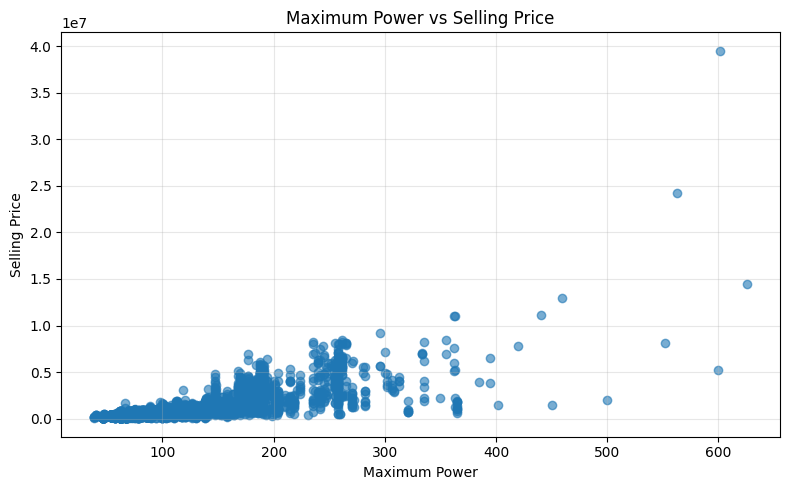

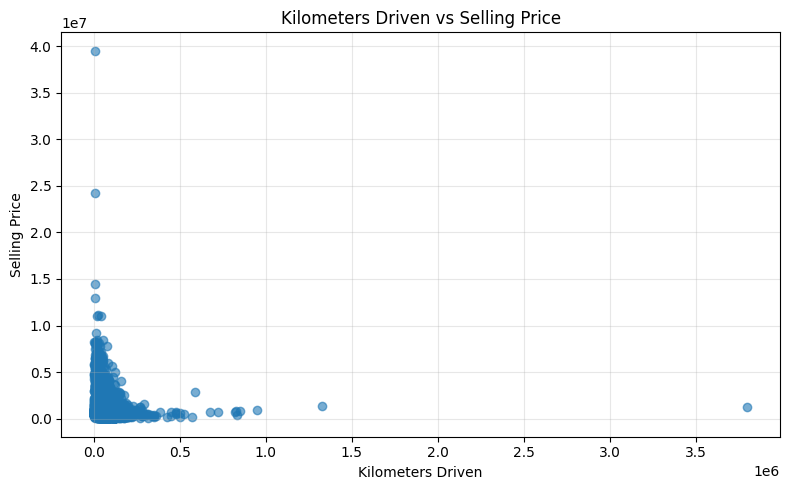

Correlation with Selling Price:
max_power: 0.750
km_driven: -0.080

Task 7 completed successfully!


In [15]:

# Task 7: Perform Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset if df is not already loaded
try:
    df
except NameError:
    df = pd.read_csv('/content/cardekho_dataset.csv')

# Identify columns without depending on capitalization
column_map = {col.strip().lower(): col for col in df.columns}

# Select target column
if 'selling_price' in column_map:
    target_col = column_map['selling_price']
else:
    raise KeyError("Selling price column was not found.")

# Select numerical predictors available in the dataset
if 'present_price' in column_map:
    predictor1 = column_map['present_price']
    predictor1_label = 'Present Price'
elif 'max_power' in column_map:
    predictor1 = column_map['max_power']
    predictor1_label = 'Maximum Power'
else:
    predictor1 = column_map.get('engine')
    predictor1_label = 'Engine Capacity'

if 'km_driven' in column_map:
    predictor2 = column_map['km_driven']
    predictor2_label = 'Kilometers Driven'
elif 'vehicle_age' in column_map:
    predictor2 = column_map['vehicle_age']
    predictor2_label = 'Vehicle Age'
else:
    predictor2 = column_map.get('mileage')
    predictor2_label = 'Mileage'

# Convert the selected columns to numeric values
df[target_col] = pd.to_numeric(df[target_col], errors='coerce')

for col in [predictor1, predictor2]:
    if col is not None:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Plot 1: Price versus present price, if available;
# otherwise use maximum power as a numerical predictor
if predictor1 is not None:
    plot_data1 = df[[predictor1, target_col]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(plot_data1[predictor1], plot_data1[target_col], alpha=0.6)
    plt.xlabel(predictor1_label)
    plt.ylabel('Selling Price')
    plt.title(f'{predictor1_label} vs Selling Price')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Plot 2: Another numerical predictor versus selling price
if predictor2 is not None:
    plot_data2 = df[[predictor2, target_col]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(plot_data2[predictor2], plot_data2[target_col], alpha=0.6)
    plt.xlabel(predictor2_label)
    plt.ylabel('Selling Price')
    plt.title(f'{predictor2_label} vs Selling Price')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Calculate correlations to support observations
print("Correlation with Selling Price:")
for col in [predictor1, predictor2]:
    if col is not None:
        correlation = df[[col, target_col]].dropna().corr().iloc[0, 1]
        print(f"{col}: {correlation:.3f}")

print("\nTask 7 completed successfully!")


## Task 8: Standardize Numerical Features

Identify the numerical predictors that need to be standardized.

Use the following standardization equation:

\[
z = ($x$-$\mu$)/$\sigma$
\]

where:

- $x$ = original feature value
- $\mu$ = mean of the feature
- $\sigma$ = standard deviation of the feature

Perform the following:

- Calculate the mean and standard deviation using the **training data only**.
- Standardize the training features.
- Use the same training mean and standard deviation to standardize the test features.
- Do not standardize the target variable `Selling_Price`.

---

In [16]:

# Task 8: Standardize Numerical Features

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load the dataset if it is not already loaded
try:
    df
except NameError:
    df = pd.read_csv('/content/cardekho_dataset.csv')

# Identify the target column
target_col = next(
    (col for col in df.columns if col.strip().lower() == 'selling_price'),
    None
)

if target_col is None:
    raise KeyError("Target column 'selling_price' was not found.")

# Create the feature matrix and target vector
# Reuse Car_Age if it was created in Task 6
data = df.copy()

if 'Car_Age' not in data.columns:
    vehicle_age_col = next(
        (col for col in data.columns if col.strip().lower() == 'vehicle_age'),
        None
    )
    if vehicle_age_col is not None:
        data['Car_Age'] = pd.to_numeric(
            data[vehicle_age_col], errors='coerce'
        )

# Drop target, identifiers, and duplicate age/year columns from predictors
drop_cols = [
    target_col, 'Unnamed: 0', 'car_name', 'name',
    'vehicle_age', 'Year'
]
drop_cols = [
    col for col in data.columns
    if col in drop_cols or col.strip().lower() in
    ['unnamed: 0', 'car_name', 'name', 'year', 'vehicle_age']
]

X_raw = data.drop(columns=drop_cols, errors='ignore').copy()
y = pd.to_numeric(data[target_col], errors='coerce')

# Convert categorical predictors to numerical dummy variables
categorical_cols = X_raw.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

X = pd.get_dummies(
    X_raw,
    columns=categorical_cols,
    drop_first=True,
    dtype=float
)

# Make sure all predictors are numeric and remove invalid rows
X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)
y = y.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows].astype(float)
y = y.loc[valid_rows].astype(float)

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Identify numerical predictor columns
numerical_cols = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

# Calculate mean and standard deviation from training data ONLY
train_mean = X_train[numerical_cols].mean()
train_std = X_train[numerical_cols].std(ddof=0)

# Prevent division by zero for constant features
train_std = train_std.replace(0, 1)

# Standardize training features
X_train_standardized = (
    X_train[numerical_cols] - train_mean
) / train_std

# Standardize test features using training mean and standard deviation
X_test_standardized = (
    X_test[numerical_cols] - train_mean
) / train_std

# Keep target variable unchanged
print("Target variable: selling_price")
print("Target variable standardized: No")

print("\nTraining set shape:", X_train_standardized.shape)
print("Test set shape:", X_test_standardized.shape)

print("\nTraining means (first 10 features):")
print(train_mean.head(10))

print("\nTraining standard deviations (first 10 features):")
print(train_std.head(10))

print("\nStandardized training data (first 5 rows):")
display(X_train_standardized.head())

print("\nStandardized test data (first 5 rows):")
display(X_test_standardized.head())

print("\nCheck training means after standardization (first 10):")
print(X_train_standardized.mean().head(10).round(4))

print("\nCheck training standard deviations after standardization (first 10):")
print(X_train_standardized.std(ddof=0).head(10).round(4))

print("\nTask 8 completed successfully!")


Target variable: selling_price
Target variable standardized: No

Training set shape: (12328, 163)
Test set shape: (3083, 163)

Training means (first 10 features):
km_driven        55423.607560
mileage             19.736975
engine            1484.194517
max_power          100.361776
seats                5.326411
Car_Age              6.025227
brand_BMW            0.028147
brand_Bentley        0.000243
brand_Datsun         0.011356
brand_Ferrari        0.000081
dtype: float64

Training standard deviations (first 10 features):
km_driven        42476.041331
mileage              4.162715
engine             521.302295
max_power           42.748575
seats                0.808302
Car_Age              3.008844
brand_BMW            0.165394
brand_Bentley        0.015598
brand_Datsun         0.105959
brand_Ferrari        0.009006
dtype: float64

Standardized training data (first 5 rows):


,km_driven,mileage,engine,max_power,seats,Car_Age,brand_BMW,brand_Bentley,brand_Datsun,brand_Ferrari,...,model_i10,model_i20,model_redi-GO,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
11210,0.349100,-2.050819,1.756765,2.681685,-0.403824,0.323969,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,1.036351,-0.015602,-0.052589,-0.991438,-1.976776
1347,-1.069394,0.985661,-0.547081,-0.382744,-0.403824,-1.337798,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,1.309283,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,0.505874
10363,-1.163564,-0.177042,0.893542,3.296910,-0.403824,-1.337798,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,1.036351,-0.015602,-0.052589,-0.991438,-1.976776
316,0.178369,-0.465315,0.024564,0.396229,-0.403824,0.323969,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,0.505874
10638,0.585469,0.149668,-0.550917,-0.502047,-0.403824,1.321030,-0.170184,-0.015602,-0.107176,-0.009007,...,6.011034,-0.25343,-0.027029,-0.763777,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,0.505874



Standardized test data (first 5 rows):


,km_driven,mileage,engine,max_power,seats,Car_Age,brand_BMW,brand_Bentley,brand_Datsun,brand_Ferrari,...,model_i10,model_i20,model_redi-GO,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Manual
3334,0.413795,0.149668,-0.550917,-0.502047,-0.403824,1.985737,-0.170184,-0.015602,-0.107176,-0.009007,...,6.011034,-0.25343,-0.027029,-0.763777,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,0.505874
10928,0.060655,1.838470,-0.453086,-0.616670,-0.403824,-0.673091,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,1.309283,-0.107176,1.036351,-0.015602,-0.052589,-0.991438,0.505874
2518,0.955277,0.248161,-0.453086,-0.271396,2.070500,0.323969,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,1.036351,-0.015602,-0.052589,-0.991438,0.505874
11322,-1.198878,-0.321179,0.026483,0.444184,-0.403824,-1.670152,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,-1.976776
9394,0.154826,-0.008882,-1.320145,-1.264645,-0.403824,1.653383,-0.170184,-0.015602,-0.107176,-0.009007,...,-0.166361,-0.25343,-0.027029,-0.763777,-0.107176,-0.964924,-0.015602,-0.052589,1.008636,0.505874



Check training means after standardization (first 10):
km_driven       -0.0
mileage          0.0
engine          -0.0
max_power        0.0
seats           -0.0
Car_Age          0.0
brand_BMW        0.0
brand_Bentley    0.0
brand_Datsun     0.0
brand_Ferrari    0.0
dtype: float64

Check training standard deviations after standardization (first 10):
km_driven        1.0
mileage          1.0
engine           1.0
max_power        1.0
seats            1.0
Car_Age          1.0
brand_BMW        1.0
brand_Bentley    1.0
brand_Datsun     1.0
brand_Ferrari    1.0
dtype: float64

Task 8 completed successfully!


## Task 9: Split the Dataset

Divide the dataset into training and testing subsets.

- Use an **80:20 train-test ratio**.
- Randomly select the observations.
- Set a fixed random seed to make the experiment reproducible.
- Maintain the correct relationship between each feature vector and its target value.
- Display the number of observations in the training and testing sets.

---

In [17]:

# Task 9: Split the Dataset into Training and Testing Sets

import pandas as pd
from sklearn.model_selection import train_test_split

# Use the processed features and target from Task 8
# X and y must contain the same observations in the same order.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Display the number of observations
print("Dataset Splitting Results")
print("--------------------------")
print("Total observations:", len(X))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining ratio: {:.0f}%".format(len(X_train) / len(X) * 100))
print("Testing ratio: {:.0f}%".format(len(X_test) / len(X) * 100))

# Verify that features and targets remain aligned
print("\nTraining feature shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Testing feature shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("\nFeature-target alignment verified.")
print("Task 9 completed successfully!")


Dataset Splitting Results
--------------------------
Total observations: 15411
Training observations: 12328
Testing observations: 3083

Training ratio: 80%
Testing ratio: 20%

Training feature shape: (12328, 163)
Training target shape: (12328,)
Testing feature shape: (3083, 163)
Testing target shape: (3083,)

Feature-target alignment verified.
Task 9 completed successfully!


## Task 10: Construct the Feature Matrix

Construct the matrices required for regression.

Create:

- $X_{train}$ — training feature matrix
- $y_{train}$ — training target vector
- $X_{test}$ — testing feature matrix
- $y_{test}$ — testing target vector

Verify:

- Number of rows in each matrix.
- Number of predictor columns.
- Shape of the training and testing matrices.

---

In [18]:

# Task 10: Construct the Feature Matrix

import numpy as np
import pandas as pd

# Check that the dataset split from Task 9 exists
required_variables = ['X_train', 'X_test', 'y_train', 'y_test']

for var in required_variables:
    if var not in globals():
        raise NameError(
            f"{var} is missing. Run Task 9 before running Task 10."
        )

# Convert feature sets to NumPy matrices
X_train_matrix = np.asarray(X_train, dtype=float)
X_test_matrix = np.asarray(X_test, dtype=float)

# Convert target vectors to NumPy arrays
y_train_vector = np.asarray(y_train, dtype=float).reshape(-1, 1)
y_test_vector = np.asarray(y_test, dtype=float).reshape(-1, 1)

# Display matrix information
print("FEATURE MATRIX CONSTRUCTION")
print("=" * 40)

print("\nTraining Data:")
print("X_train shape:", X_train_matrix.shape)
print("y_train shape:", y_train_vector.shape)
print("Number of training observations:", X_train_matrix.shape[0])
print("Number of predictor columns:", X_train_matrix.shape[1])

print("\nTesting Data:")
print("X_test shape:", X_test_matrix.shape)
print("y_test shape:", y_test_vector.shape)
print("Number of testing observations:", X_test_matrix.shape[0])
print("Number of predictor columns:", X_test_matrix.shape[1])

# Verify row counts and feature consistency
assert X_train_matrix.shape[0] == y_train_vector.shape[0]
assert X_test_matrix.shape[0] == y_test_vector.shape[0]
assert X_train_matrix.shape[1] == X_test_matrix.shape[1]

print("\nVerification:")
print("Training features and targets have matching rows.")
print("Testing features and targets have matching rows.")
print("Training and testing have the same predictor columns.")

print("\nFirst 5 rows of X_train:")
print(X_train_matrix[:5])

print("\nFirst 5 training target values:")
print(y_train_vector[:5])

print("\nTask 10 completed successfully!")


FEATURE MATRIX CONSTRUCTION

Training Data:
X_train shape: (12328, 163)
y_train shape: (12328, 1)
Number of training observations: 12328
Number of predictor columns: 163

Testing Data:
X_test shape: (3083, 163)
y_test shape: (3083, 1)
Number of testing observations: 3083
Number of predictor columns: 163

Verification:
Training features and targets have matching rows.
Testing features and targets have matching rows.
Training and testing have the same predictor columns.

First 5 rows of X_train:
[[7.0252e+04 1.1200e+01 2.4000e+03 2.1500e+02 5.0000e+00 7.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0

## Task 11: Add the Bias/Intercept Term

Add a leading column containing $1.0$ to both the training and testing feature matrices.

The resulting matrices should contain:

\[
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1p}\\
1 & x_{21} & x_{22} & \cdots & x_{2p}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix}
\]

Perform the following:

- Add the bias column.
- Verify the new matrix dimensions.
- Understand that the first column represents the intercept $\beta_0$.

---

In [19]:

# Task 11: Add the Bias/Intercept Term

import numpy as np

# Check that matrices from Task 10 exist
if 'X_train_matrix' not in globals() or 'X_test_matrix' not in globals():
    raise NameError("Please run Task 10 first to construct the feature matrices.")

# Add a leading column of ones to the training matrix
X_train_bias = np.c_[
    np.ones((X_train_matrix.shape[0], 1)),
    X_train_matrix
]

# Add a leading column of ones to the testing matrix
X_test_bias = np.c_[
    np.ones((X_test_matrix.shape[0], 1)),
    X_test_matrix
]

# Display the original and new dimensions
print("TASK 11: ADD BIAS / INTERCEPT TERM")
print("=" * 40)

print("\nBefore adding bias:")
print("Training matrix shape:", X_train_matrix.shape)
print("Testing matrix shape:", X_test_matrix.shape)

print("\nAfter adding bias:")
print("Training matrix shape:", X_train_bias.shape)
print("Testing matrix shape:", X_test_bias.shape)

# Verify dimensions
assert X_train_bias.shape[0] == X_train_matrix.shape[0]
assert X_test_bias.shape[0] == X_test_matrix.shape[0]

assert X_train_bias.shape[1] == X_train_matrix.shape[1] + 1
assert X_test_bias.shape[1] == X_test_matrix.shape[1] + 1

# Verify that the first column contains only ones
assert np.all(X_train_bias[:, 0] == 1.0)
assert np.all(X_test_bias[:, 0] == 1.0)

print("\nFirst 5 rows of the training matrix with bias:")
print(X_train_bias[:5])

print("\nFirst 5 rows of the testing matrix with bias:")
print(X_test_bias[:5])

print("\nVerification successful!")
print("The first column represents the intercept coefficient beta_0.")
print("Task 11 completed successfully!")


TASK 11: ADD BIAS / INTERCEPT TERM

Before adding bias:
Training matrix shape: (12328, 163)
Testing matrix shape: (3083, 163)

After adding bias:
Training matrix shape: (12328, 164)
Testing matrix shape: (3083, 164)

First 5 rows of the training matrix with bias:
[[1.0000e+00 7.0252e+04 1.1200e+01 2.4000e+03 2.1500e+02 5.0000e+00
  7.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00

## Task 12: Implement the OLS Function

Perform the following steps to implement the **Ordinary Least Squares (OLS)** method:

- Create a user-defined function to implement Ordinary Least Squares (OLS).
- Calculate the matrix $X^TX$.
- Calculate the matrix $X^T y$.
- Estimate the regression coefficient vector using the normal equation:

: β̂ = (XᵀX)⁻¹Xᵀy.

- Return the calculated coefficient vector.
- Use **NumPy matrix operations** to perform the calculations.
- Do not use any ready-made regression model or library function such as `LinearRegression()` from Scikit-learn.\

In [21]:

# Task 12: Implement the OLS Function Using NumPy

import numpy as np

def OLS(X, y):
    """
    Implement Ordinary Least Squares using the normal equation.

    Parameters:
        X : Feature matrix with a bias/intercept column
        y : Target vector

    Returns:
        beta : Estimated regression coefficient vector
    """

    # Convert inputs into NumPy arrays
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)

    # Step 1: Calculate X transpose
    X_T = X.T

    # Step 2: Calculate X^T X
    XTX = X_T @ X

    # Step 3: Calculate X^T y
    XTy = X_T @ y

    # Step 4: Estimate regression coefficients
    # Use inverse when X^T X is invertible
    try:
        beta = np.linalg.inv(XTX) @ XTy
    except np.linalg.LinAlgError:
        # Fallback if X^T X is singular
        print("Warning: X^T X is singular. Using pseudoinverse.")
        beta = np.linalg.pinv(XTX) @ XTy

    return beta


# Fit the OLS model using the training data
beta_hat = OLS(X_train_bias, y_train_vector)

# Display the estimated coefficients
print("OLS Regression Coefficients")
print("=" * 35)
print("Coefficient vector shape:", beta_hat.shape)
print("\nEstimated coefficients:")

for i, coefficient in enumerate(beta_hat.flatten()):
    if i == 0:
        print(f"Beta_0 (Intercept): {coefficient:.4f}")
    else:
        print(f"Beta_{i}: {coefficient:.4f}")

print("\nTask 12 completed successfully!")


OLS Regression Coefficients
Coefficient vector shape: (164, 1)

Estimated coefficients:
Beta_0 (Intercept): 3375785.3460
Beta_1: -0.9419
Beta_2: -2999.8832
Beta_3: -231.1306
Beta_4: 5730.8802
Beta_5: -27225.7268
Beta_6: -77273.6782
Beta_7: -1434645.9914
Beta_8: 2392722.0343
Beta_9: -1915433.3295
Beta_10: 16921931.1677
Beta_11: -981339.5344
Beta_12: -1745209.0992
Beta_13: -1797831.4278
Beta_14: -1986703.7170
Beta_15: -652692.4668
Beta_16: -926997.6979
Beta_17: 78866.8436
Beta_18: -111079.2802
Beta_19: -809075.5699
Beta_20: 202833.9951
Beta_21: 1504529.7608
Beta_22: -892402.2924
Beta_23: -1821536.7200
Beta_24: -2195163.5180
Beta_25: 1591977.0762
Beta_26: -0.0001
Beta_27: 36990.2167
Beta_28: -415655.9416
Beta_29: -1467470.9956
Beta_30: 1177491.4144
Beta_31: -1808178.8238
Beta_32: 9778511.4681
Beta_33: -1546885.9447
Beta_34: -1989460.6299
Beta_35: -1415652.3739
Beta_36: -1532608.8487
Beta_37: 34961.9243
Beta_38: 951738.2997
Beta_39: 2667009.9031
Beta_40: 1842942.8939
Beta_41: -1522680.7907

## Task 13: Check Matrix Singularity

- Calculate the determinant of $X^T X$.
- Check whether the determinant is zero or sufficiently close to zero.
- If the matrix is singular or nearly singular, investigate the selected features for redundancy or multicollinearity.
- Modify the feature set if required.
- Record your observations.


In [22]:

# Task 13: Check Matrix Singularity

import numpy as np
import pandas as pd

# Use the training matrix with the bias column from Task 11
if 'X_train_bias' not in globals():
    raise NameError("Please run Task 11 first.")

# Step 1: Calculate X^T X
XTX = X_train_bias.T @ X_train_bias

print("X^T X Matrix Shape:", XTX.shape)

# Step 2: Calculate determinant
det_XTX = np.linalg.det(XTX)

print("\nDeterminant of X^T X:", det_XTX)

# Step 3: Check determinant and matrix rank
matrix_rank = np.linalg.matrix_rank(X_train_bias)
num_columns = X_train_bias.shape[1]

print("Matrix rank:", matrix_rank)
print("Number of columns:", num_columns)

if matrix_rank < num_columns:
    print("\nResult: The feature matrix is rank-deficient.")
    print("This indicates exact linear dependence among columns.")
elif np.isclose(det_XTX, 0.0, atol=1e-8):
    print("\nResult: The determinant is close to zero.")
    print("The matrix may be ill-conditioned or nearly singular.")
else:
    print("\nResult: The determinant is not close to zero.")
    print("The matrix may be invertible; check its condition number too.")

# Step 4: Check the condition number for numerical stability
condition_number = np.linalg.cond(X_train_bias)

print("\nCondition number of X_train_bias:", condition_number)

if not np.isfinite(condition_number) or condition_number > 1e10:
    print("Warning: The matrix may be poorly conditioned.")
else:
    print("Condition number check completed.")

# Step 5: Check for perfectly correlated predictor columns
# Exclude the bias column
X_predictors = X_train_bias[:, 1:]

if X_predictors.shape[1] > 1:
    corr_matrix = np.corrcoef(X_predictors, rowvar=False)
    corr_matrix = np.atleast_2d(corr_matrix)

    # Find pairs with absolute correlation near 1
    highly_correlated_pairs = []
    for i in range(corr_matrix.shape[0]):
        for j in range(i + 1, corr_matrix.shape[1]):
            if np.isfinite(corr_matrix[i, j]) and abs(corr_matrix[i, j]) >= 0.999:
                highly_correlated_pairs.append(
                    (i + 1, j + 1, corr_matrix[i, j])
                )

    print("\nPairs of predictor columns with correlation near +/-1:")
    if highly_correlated_pairs:
        for col1, col2, corr in highly_correlated_pairs:
            print(f"Column {col1} and Column {col2}: correlation = {corr:.6f}")
    else:
        print("No perfectly or almost perfectly correlated pairs found.")
else:
    print("\nNot enough predictor columns to check pairwise correlation.")

# Step 6: Show feature names if available
if 'X_train' in globals():
    print("\nPredictor feature names:")
    print(list(X_train.columns))

print("\nTask 13 completed successfully!")


X^T X Matrix Shape: (164, 164)

Determinant of X^T X: 0.0
Matrix rank: 131
Number of columns: 164

Result: The feature matrix is rank-deficient.
This indicates exact linear dependence among columns.

Condition number of X_train_bias: 3.907548542749889e+23

Pairs of predictor columns with correlation near +/-1:
Column 8 and Column 65: correlation = 1.000000
Column 10 and Column 87: correlation = 1.000000
Column 11 and Column 92: correlation = 1.000000
Column 15 and Column 103: correlation = 1.000000
Column 16 and Column 68: correlation = 1.000000
Column 20 and Column 116: correlation = 1.000000
Column 22 and Column 94: correlation = 1.000000
Column 28 and Column 66: correlation = 1.000000
Column 32 and Column 89: correlation = 1.000000

Predictor feature names:
['km_driven', 'mileage', 'engine', 'max_power', 'seats', 'Car_Age', 'brand_BMW', 'brand_Bentley', 'brand_Datsun', 'brand_Ferrari', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_ISUZU', 'brand_Isuzu', 'brand_

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Task 14: Train the Regression Model

- Apply the OLS function to the training dataset.
- Obtain the regression coefficient vector $\hat{\beta}$.
- Display the intercept coefficient $\beta_0$.
- Display the coefficient corresponding to each feature.
- Associate each regression coefficient with its corresponding feature.

In [23]:

# Task 14: Train the Regression Model using OLS

import numpy as np
import pandas as pd

# Step 1: Check that the required variables exist
required_vars = ['X_train_bias', 'y_train_vector', 'OLS']

for var in required_vars:
    if var not in globals():
        raise NameError(f"{var} is missing. Run the previous tasks first.")

# Step 2: Train the model using the OLS function
beta_hat = OLS(X_train_bias, y_train_vector)

# Step 3: Display the intercept
intercept = beta_hat[0, 0]

print("OLS REGRESSION MODEL")
print("=" * 50)
print(f"Intercept (Beta_0): {intercept:.6f}")

# Step 4: Associate coefficients with feature names
# The first coefficient is the intercept, so the remaining
# coefficients correspond to the predictor columns.
if 'X_train' in globals():
    feature_names = list(X_train.columns)
else:
    feature_names = [
        f"Feature_{i}" for i in range(1, X_train_bias.shape[1])
    ]

coefficients = beta_hat.flatten()[1:]

# Step 5: Display all regression coefficients
coefficient_table = pd.DataFrame({
    'Feature': feature_names,
    'Regression Coefficient': coefficients
})

print("\nRegression Coefficients for Each Feature:")
display(coefficient_table)

# Step 6: Display the complete coefficient vector
print("\nComplete Coefficient Vector (Beta Hat):")
print(beta_hat)

# Step 7: Verify dimensions
print("\nVerification:")
print("Number of coefficients:", len(beta_hat))
print("Expected coefficients:", X_train_bias.shape[1])
print("Number of predictor features:", len(feature_names))

assert len(beta_hat) == X_train_bias.shape[1]
assert len(feature_names) == len(coefficients)

print("\nTask 14 completed successfully!")


OLS REGRESSION MODEL
Intercept (Beta_0): 3375785.346037

Regression Coefficients for Each Feature:


,Feature,Regression Coefficient
0,km_driven,-0.941861
1,mileage,-2999.883178
2,engine,-231.130572
3,max_power,5730.880160
4,seats,-27225.726783
...,...,...
158,fuel_type_Diesel,113918.372834
159,fuel_type_Electric,322957.711970
160,fuel_type_LPG,200268.214389
161,fuel_type_Petrol,-16533.145685



Complete Coefficient Vector (Beta Hat):
[[ 3.37578535e+06]
 [-9.41861435e-01]
 [-2.99988318e+03]
 [-2.31130572e+02]
 [ 5.73088016e+03]
 [-2.72257268e+04]
 [-7.72736782e+04]
 [-1.43464599e+06]
 [ 2.39272203e+06]
 [-1.91543333e+06]
 [ 1.69219312e+07]
 [-9.81339534e+05]
 [-1.74520910e+06]
 [-1.79783143e+06]
 [-1.98670372e+06]
 [-6.52692467e+05]
 [-9.26997698e+05]
 [ 7.88668436e+04]
 [-1.11079280e+05]
 [-8.09075570e+05]
 [ 2.02833995e+05]
 [ 1.50452976e+06]
 [-8.92402292e+05]
 [-1.82153672e+06]
 [-2.19516352e+06]
 [ 1.59197708e+06]
 [-1.08501096e-04]
 [ 3.69902167e+04]
 [-4.15655942e+05]
 [-1.46747100e+06]
 [ 1.17749141e+06]
 [-1.80817882e+06]
 [ 9.77851147e+06]
 [-1.54688594e+06]
 [-1.98946063e+06]
 [-1.41565237e+06]
 [-1.53260885e+06]
 [ 3.49619243e+04]
 [ 9.51738300e+05]
 [ 2.66700990e+06]
 [ 1.84294289e+06]
 [-1.52268079e+06]
 [-1.14064222e+06]
 [-1.67650175e+04]
 [-1.30251560e+05]
 [-4.77234869e+05]
 [ 8.56397272e+05]
 [-6.10170905e+05]
 [-6.97816014e+05]
 [-2.82057184e+05]
 [-1.4974

## Task 15: Interpret the Regression Coefficients

- Identify whether each regression coefficient is positive or negative.
- Explain what the sign of each coefficient indicates.
- Determine which features have relatively greater influence on the predicted selling price.
- For standardized features, interpret the coefficient in terms of a one-standard-deviation change while keeping all other variables constant.

In [24]:

# Task 15: Interpret the Regression Coefficients

import numpy as np
import pandas as pd

# Check that the trained coefficients and feature names exist
if 'beta_hat' not in globals():
    raise NameError("Please run Task 14 first.")

if 'X_train' not in globals():
    raise NameError("X_train is missing. Please run the previous tasks.")

# Extract intercept and predictor coefficients
intercept = float(np.asarray(beta_hat).flatten()[0])
coefficients = np.asarray(beta_hat).flatten()[1:]
feature_names = list(X_train.columns)

# Create a table associating features with coefficients
results = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Identify coefficient signs
results['Coefficient Sign'] = np.where(
    results['Coefficient'] > 0,
    'Positive',
    np.where(results['Coefficient'] < 0, 'Negative', 'Zero')
)

# Absolute values help compare coefficient magnitudes
results['Absolute Coefficient'] = results['Coefficient'].abs()

# Interpret direction
results['Interpretation'] = np.where(
    results['Coefficient'] > 0,
    'Increase in feature is associated with higher predicted selling price',
    np.where(
        results['Coefficient'] < 0,
        'Increase in feature is associated with lower predicted selling price',
        'No linear change indicated by this coefficient'
    )
)

print("Intercept (Beta_0):", round(intercept, 6))
print("\nCoefficient Interpretation:")
display(results.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True))

# Show the features with the largest absolute coefficients
print("\nTop 10 Features by Absolute Coefficient:")
display(
    results.nlargest(10, 'Absolute Coefficient')[
        ['Feature', 'Coefficient', 'Coefficient Sign']
    ]
)

print("\nTask 15 completed successfully!")


Intercept (Beta_0): 3375785.346037

Coefficient Interpretation:


,Feature,Coefficient,Coefficient Sign,Absolute Coefficient,Interpretation
0,brand_Ferrari,1.692193e+07,Positive,1.692193e+07,Increase in feature is associated with higher ...
1,model_GTC4Lusso,1.692193e+07,Positive,1.692193e+07,Increase in feature is associated with higher ...
2,brand_Rolls-Royce,9.778511e+06,Positive,9.778511e+06,Increase in feature is associated with higher ...
3,model_Ghost,9.778511e+06,Positive,9.778511e+06,Increase in feature is associated with higher ...
4,model_X4,3.253581e+06,Positive,3.253581e+06,Increase in feature is associated with higher ...
...,...,...,...,...,...
158,engine,-2.311306e+02,Negative,2.311306e+02,Increase in feature is associated with lower p...
159,km_driven,-9.418614e-01,Negative,9.418614e-01,Increase in feature is associated with lower p...
160,brand_Mercedes-AMG,-1.085011e-04,Negative,1.085011e-04,Increase in feature is associated with lower p...
161,model_C,-9.092393e-06,Negative,9.092393e-06,Increase in feature is associated with lower p...



Top 10 Features by Absolute Coefficient:


,Feature,Coefficient,Coefficient Sign
9,brand_Ferrari,1.692193e+07,Positive
86,model_GTC4Lusso,1.692193e+07,Positive
31,brand_Rolls-Royce,9.778511e+06,Positive
88,model_Ghost,9.778511e+06,Positive
141,model_X4,3.253581e+06,Positive
84,model_GLS,2.936844e+06,Positive
38,model_6,2.667010e+06,Positive
64,model_Continental,2.392722e+06,Positive
7,brand_Bentley,2.392722e+06,Positive
23,brand_Maruti,-2.195164e+06,Negative



Task 15 completed successfully!


## Task 16: Predict Selling Prices

- Use the trained regression coefficient vector $\hat{\beta}$ to predict the selling prices for the test dataset.
- Calculate the predicted values using the equation: ŷ_test = X_test β̂.

- Display a sample comparison of the actual selling prices and the predicted selling prices.

In [25]:

# Task 16: Predict Selling Prices

import numpy as np
import pandas as pd

# Step 1: Predict selling prices using the trained coefficients
# X_test_bias already contains the bias/intercept column of ones.
# beta_hat contains the trained regression coefficients.

y_pred = X_test_bias @ beta_hat

# Step 2: Convert actual and predicted values into 1D arrays
actual_prices = np.asarray(y_test_vector).flatten()
predicted_prices = np.asarray(y_pred).flatten()

# Step 3: Create a comparison table
comparison = pd.DataFrame({
    'Actual Selling Price': actual_prices,
    'Predicted Selling Price': predicted_prices
})

# Step 4: Display the first 10 comparisons
print("Actual vs Predicted Selling Prices (First 10 Test Samples):")
display(comparison.head(10))

# Step 5: Display the shape of predictions
print("\nNumber of predictions:", len(predicted_prices))
print("Prediction array shape:", y_pred.shape)


Actual vs Predicted Selling Prices (First 10 Test Samples):


,Actual Selling Price,Predicted Selling Price
0,190000.0,7.129231e+04
1,600000.0,6.151994e+05
2,665000.0,6.254577e+05
3,1570000.0,1.222457e+06
4,160000.0,-5.591521e+04
5,675000.0,4.326369e+05
6,465000.0,3.198022e+05
7,260000.0,2.525548e+05
8,300000.0,3.601697e+05
9,850000.0,1.837039e+06



Number of predictions: 3083
Prediction array shape: (3083, 1)


## Task 17: Calculate Prediction Errors and RSS

- Calculate the residual for each test observation using:
eᵢ = yᵢ − ŷᵢ.

- Calculate the **Residual Sum of Squares (RSS): RSS = Σ(yᵢ − ŷᵢ)².

- Display the calculated RSS value.
- Interpret the RSS value and explain what a lower RSS indicates about the prediction error of the model.

In [26]:

# Task 17: Calculate Prediction Errors and RSS

import numpy as np
import pandas as pd

# Step 1: Calculate residuals
# Residual = Actual Selling Price - Predicted Selling Price
residuals = actual_prices - predicted_prices

# Step 2: Calculate squared residuals
squared_residuals = residuals ** 2

# Step 3: Calculate Residual Sum of Squares (RSS)
RSS = np.sum(squared_residuals)

# Step 4: Display sample residual calculations
error_table = pd.DataFrame({
    'Actual Selling Price': actual_prices,
    'Predicted Selling Price': predicted_prices,
    'Residual': residuals,
    'Squared Residual': squared_residuals
})

print("Sample Prediction Errors (First 10 Test Samples):")
display(error_table.head(10))

# Step 5: Display RSS
print("Residual Sum of Squares (RSS):", RSS)
print("Total Test Observations:", len(residuals))


Sample Prediction Errors (First 10 Test Samples):


,Actual Selling Price,Predicted Selling Price,Residual,Squared Residual
0,190000.0,7.129231e+04,118707.687566,1.409152e+10
1,600000.0,6.151994e+05,-15199.416512,2.310223e+08
2,665000.0,6.254577e+05,39542.258300,1.563590e+09
3,1570000.0,1.222457e+06,347543.225418,1.207863e+11
4,160000.0,-5.591521e+04,215915.213048,4.661938e+10
5,675000.0,4.326369e+05,242363.106659,5.873988e+10
6,465000.0,3.198022e+05,145197.805257,2.108240e+10
7,260000.0,2.525548e+05,7445.248461,5.543172e+07
8,300000.0,3.601697e+05,-60169.695524,3.620392e+09
9,850000.0,1.837039e+06,-987039.208605,9.742464e+11


Residual Sum of Squares (RSS): 464715810144921.4
Total Test Observations: 3083


## Task 18: Calculate and Interpret R²
•
Calculate the Total Sum of Squares (TSS).

•
Calculate R² = 1 − RSS/TSS.

•
Display the R² value.

•
Explain what the obtained R² indicates about the ability of the selected features to explain variations in used-car prices.



In [27]:

# Task 18: Calculate and Interpret R²

import numpy as np

# Step 1: Calculate the Total Sum of Squares (TSS)
# TSS measures the total variation in actual selling prices
mean_actual_price = np.mean(actual_prices)

TSS = np.sum((actual_prices - mean_actual_price) ** 2)

# Step 2: Calculate R-squared
if TSS != 0:
    R_squared = 1 - (RSS / TSS)
else:
    R_squared = np.nan

# Step 3: Display the results
print("Total Sum of Squares (TSS):", TSS)
print("Residual Sum of Squares (RSS):", RSS)
print("R-squared (R²):", R_squared)

# Step 4: Interpret the result
if np.isnan(R_squared):
    print("R² cannot be calculated because all actual test prices are identical.")
elif R_squared >= 0.75:
    print("Interpretation: The model explains a large proportion of the variation in used-car prices.")
elif R_squared >= 0.50:
    print("Interpretation: The model explains a moderate proportion of the variation in used-car prices.")
elif R_squared >= 0:
    print("Interpretation: The model explains a limited proportion of the variation in used-car prices.")
else:
    print("Interpretation: The model performs worse than predicting the mean actual selling price for every test observation.")


Total Sum of Squares (TSS): 2320826260059733.0
Residual Sum of Squares (RSS): 464715810144921.4
R-squared (R²): 0.7997627749468155
Interpretation: The model explains a large proportion of the variation in used-car prices.


### Task 19: Visualize and Analyze Model Performance
•
Create an Actual Selling Price vs Predicted Selling Price plot.

•
Add a reference line representing perfect prediction.

•
Plot or examine the residuals.

•
Identify observations with relatively large prediction errors.

•
Comment on whether the errors appear randomly distributed.

•
Discuss possible reasons for prediction errors.


Sample Actual vs Predicted Prices:


,Actual Selling Price,Predicted Selling Price,Residual,Absolute Error
0,190000.0,7.129231e+04,118707.687566,118707.687566
1,600000.0,6.151994e+05,-15199.416512,15199.416512
2,665000.0,6.254577e+05,39542.258300,39542.258300
3,1570000.0,1.222457e+06,347543.225418,347543.225418
4,160000.0,-5.591521e+04,215915.213048,215915.213048
5,675000.0,4.326369e+05,242363.106659,242363.106659
6,465000.0,3.198022e+05,145197.805257,145197.805257
7,260000.0,2.525548e+05,7445.248461,7445.248461
8,300000.0,3.601697e+05,-60169.695524,60169.695524
9,850000.0,1.837039e+06,-987039.208605,987039.208605



10 Observations with the Largest Prediction Errors:


,Actual Selling Price,Predicted Selling Price,Residual,Absolute Error
500,13000000.0,4.296576e+06,8.703424e+06,8.703424e+06
2393,8150000.0,3.520176e+06,4.629824e+06,4.629824e+06
1157,8250000.0,4.429445e+06,3.820555e+06,3.820555e+06
1263,8100000.0,4.296301e+06,3.803699e+06,3.803699e+06
886,1225000.0,-2.465965e+06,3.690965e+06,3.690965e+06
2039,7985000.0,4.299457e+06,3.685543e+06,3.685543e+06
441,7900000.0,4.272421e+06,3.627579e+06,3.627579e+06
997,7595000.0,4.531610e+06,3.063390e+06,3.063390e+06
723,750000.0,3.688542e+06,-2.938542e+06,2.938542e+06
166,5275000.0,2.596655e+06,2.678345e+06,2.678345e+06


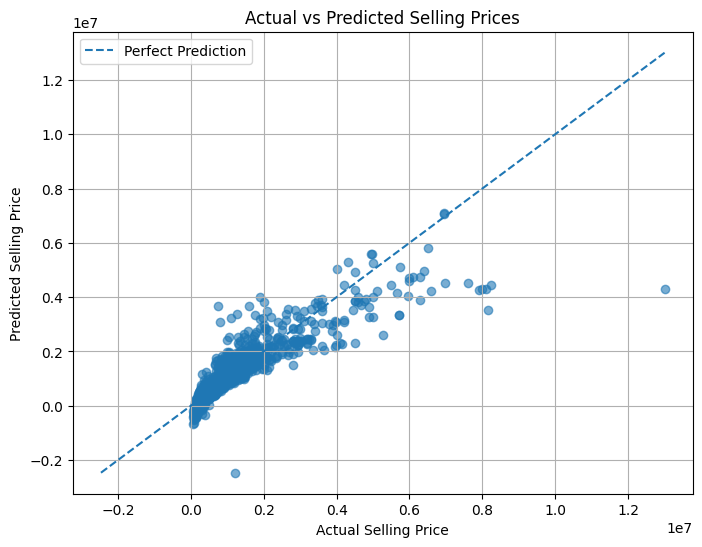

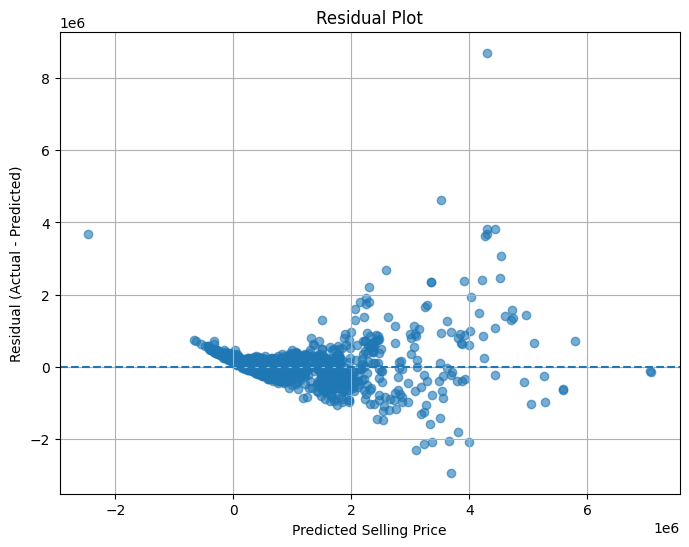


Residual Analysis:
Mean Residual: 4554.243831083611
Mean Absolute Error: 177803.46350821524
Maximum Absolute Error: 8703423.705793437
The model underpredicts prices on average.

Check the residual plot: randomly scattered points around zero suggest a reasonable fit. Curves, clusters, or widening spread may indicate patterns the model has not captured.


In [29]:

# Task 19: Visualize and Analyze Model Performance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Prepare actual and predicted prices
actual_prices = np.asarray(actual_prices).flatten()
predicted_prices = np.asarray(predicted_prices).flatten()

# Step 2: Calculate residuals and absolute errors
residuals = actual_prices - predicted_prices
absolute_errors = np.abs(residuals)

# Step 3: Create error analysis table
error_analysis = pd.DataFrame({
    'Actual Selling Price': actual_prices,
    'Predicted Selling Price': predicted_prices,
    'Residual': residuals,
    'Absolute Error': absolute_errors
})

print("Sample Actual vs Predicted Prices:")
display(error_analysis.head(10))

# Step 4: Identify observations with the largest errors
print("\n10 Observations with the Largest Prediction Errors:")
display(
    error_analysis
    .sort_values(by='Absolute Error', ascending=False)
    .head(10)
)

# Step 5: Plot actual vs predicted selling prices
plt.figure(figsize=(8, 6))
plt.scatter(actual_prices, predicted_prices, alpha=0.6)

# Reference line for perfect predictions
min_price = min(actual_prices.min(), predicted_prices.min())
max_price = max(actual_prices.max(), predicted_prices.max())
plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.title('Actual vs Predicted Selling Prices')
plt.legend()
plt.grid(True)
plt.show()

# Step 6: Plot residuals
plt.figure(figsize=(8, 6))
plt.scatter(predicted_prices, residuals, alpha=0.6)
plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Selling Price')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.grid(True)
plt.show()

# Step 7: Analyze the residuals
print("\nResidual Analysis:")
print("Mean Residual:", np.mean(residuals))
print("Mean Absolute Error:", np.mean(absolute_errors))
print("Maximum Absolute Error:", np.max(absolute_errors))

if np.mean(residuals) > 0:
    print("The model underpredicts prices on average.")
elif np.mean(residuals) < 0:
    print("The model overpredicts prices on average.")
else:
    print("The average residual is approximately zero.")

print(
    "\nCheck the residual plot: randomly scattered points around zero "
    "suggest a reasonable fit. Curves, clusters, or widening spread "
    "may indicate patterns the model has not captured."
)


### Task 20: Conclude
•
Comment on the most influential features.

•
Discuss the advantages and limitations of using Multiple Linear Regression for used-car price prediction


1. Most Influential Features :
The most influential features can be identified by examining the regression coefficients calculated in Task 15. Features with larger absolute coefficients may have a stronger influence on predictions, provided their scales are comparable.
- Vehicle age (Car_Age): Older vehicles may have lower selling prices due to depreciation.
- Kilometres driven (km_driven): Cars driven for longer distances may have lower prices.
- Maximum power (max_power): Vehicles with higher power may command higher prices, depending on other factors.
- Engine capacity (engine): Engine size may affect a vehicle's market value.
- Brand and fuel type: These categorical features may influence resale value because of brand demand, fuel preferences, and maintenance costs.
The actual ranking of influential features should be based on the coefficient values obtained from your model. These relationships are associations, not necessarily causal effects.

2. Advantages of Multiple Linear Regression
1. Simple to implement: It can be implemented using NumPy matrix operations and the Ordinary Least Squares method.
2. Easy to interpret: Regression coefficients help explain how features relate to predicted selling prices.
3. Uses multiple features: It considers several vehicle characteristics simultaneously.
4. Provides a baseline model: It offers a useful starting point for comparing more advanced regression techniques.
5. Computationally efficient: It is generally fast to train on small and medium-sized datasets.
3. Limitations of Multiple Linear Regression
1. Assumes linear relationships: It may not capture complex, nonlinear relationships between vehicle features and prices.
2. Sensitive to outliers: Unusually high or low selling prices can affect the fitted coefficients.
3. Multicollinearity: Highly correlated features, such as engine capacity and maximum power, can make coefficient estimates unstable.
4. Limited feature information: Important factors such as vehicle condition, accident history, service records, and local market demand may not be available.
5. Prediction errors: The model may produce inaccurate predictions for unusual vehicles or changing market conditions.

### Conclusion
Conclude the experiment by stating whether the Multiple Linear Regression model implemented using the OLS normal equation was able to predict used-car selling prices effectively. The conclusion should include the obtained RSS and R² values, observations regarding important features, the effect of preprocessing and feature engineering, and the limitations of using a linear regression model for real-world used-car price prediction.